# Снижение активности по картам: кто упал, насколько и за счёт чего

**Автор:** Рудьман Иван Олегович

**Данные:** Анализ 2024-01-01 — 2025-06-30 (база — 2024 год, оценка — январь–июнь 2025)

**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Сборка: jupyter nbconvert --to webpdf --no-input --execute 02_report.ipynb --output report.pdf
Лимиты: не более 6 страниц и не более 8 графиков. Кода читатель не видит, все графики
и таблицы получены исполнением, числа в тексте совпадают с выводом кода.
-->

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2, "axes.axisbelow": True})

END = pd.Timestamp("2025-06-30")

clean = pd.read_parquet("clean/clean_data.parquet")      # клиенты когорты с метрикой активности (01_analysis)
ops = pd.read_parquet("clean/clean_ops.parquet")         # операции той же когорты
campaign = pd.read_csv("campaign_list.csv")
cleaning_log = pd.read_csv("cleaning_log.csv")
funnel = pd.read_csv("clean/clean_funnel.csv")

LABEL = {
    "Массовый без приложения — ушли из повседневных трат": "Массовый без приложения",
    "Массовый с приложением — реже повседневные покупки": "Массовый с приложением",
    "Зарплатный — ровное падение по всем категориям": "Зарплатный",
    "Премиальный — реже транспорт и рестораны": "Премиальный",
}
ORDER = list(LABEL.values())
campaign["group_short"] = campaign["group"].map(LABEL)

data = clean.merge(campaign, on="client_id", how="left")
last_op = ops.groupby("client_id")["txn_datetime"].max()
data["days_idle"] = (END - data["client_id"].map(last_op)).dt.days
data["loss"] = (data["2024_activity"] - data["2025_activity"].fillna(0)).clip(lower=0)

groups_data = data.loc[data["group_short"].notna()]
COHORT_LOSS = data["loss"].sum()
CATEGORIES = sorted(ops["category"].unique())


def cat_delta(part):
    """операций на клиента в месяц по категориям: H1 2025 минус 2024."""
    n = part["client_id"].nunique()
    p = ops[ops["client_id"].isin(part["client_id"])]
    by = (
        p.groupby([p["txn_datetime"].dt.year, "category"], observed=True)
        .size()
        .unstack(fill_value=0)
        .reindex(index=[2024, 2025], columns=CATEGORIES, fill_value=0)
    )
    return by.loc[2025] / n / 6 - by.loc[2024] / n / 12


BG_CAT = cat_delta(clean)          # фон когорты: общий тренд банка

# операций на клиента в месяц по одним и тем же месяцам 2024 и 2025
monthly = (
    ops.assign(y=ops["txn_datetime"].dt.year, m=ops["txn_datetime"].dt.month)
    .groupby(["m", "y"], observed=True)
    .size()
    .unstack()
    .loc[1:6]
    / len(clean)
)
MONTHS = ["янв", "фев", "мар", "апр", "май", "июн"]

from IPython.display import HTML, display

display(HTML("""
<style>
.jp-RenderedMarkdown, .rendered_html { font-size: 9pt !important; }

/* отступы между секциями */
.jp-Cell { padding: 0 !important; margin: 0 !important; }
.jp-Cell + .jp-Cell { margin-top: 2px !important; }

/* таблицы */
table.dataframe th, table.dataframe td,
.jp-RenderedHTMLCommon table th, .jp-RenderedHTMLCommon table td {
    font-size: 9pt !important;
    padding: 2px 5px !important;
    line-height: 1.15 !important;
}
table.dataframe, .jp-RenderedHTMLCommon table {
    border-collapse: collapse !important;
    margin: 0.2em 0 !important;
}
</style>
"""))

## 1. Главное

1. **Активность падает у большинства.** Медиана по клиенту −18.9 % (январь–июнь 2025 к 2024 году), реже платят 69.4 % клиентов, суммарно когорта теряет 7 056 операций в месяц.
2. **Это не сезонность и не календарь:** в каждом из шести месяцев H1 2025 темп ниже того же месяца 2024 года на 8.4–15.1 %.
3. **Глубже всех падает массовый сегмент** — медиана −50.6 % против −22.7…−27.9 % у зарплатного, премиального и Private; внутри массового хуже всех клиенты без мобильного приложения (−63.6 %, 599 человек).
4. **Причина — повседневные траты, а не переток между категориями:** «Продукты» дают 33.1 % потери у массового без приложения и 32.2 % с приложением, у премиального на первом месте «Транспорт» — 26.4 %. Роста нет ни в одной из 9 категорий ни в одной группе.
5. **В кампанию идут 1 962 клиента в 4 группах** (лимит 2 000, минимум 150 в группе), это 77.5 % всей потери активности. У 41.2 % группы «массовый без приложения» больше 30 дней без операций — карта выпала из ежедневного оборота.

## 2. Контекст

Департамент розничных продуктов готовит кампанию по возврату активности клиентов по картам. Бюджет — 2 000 клиентов, нужно 3–5 групп по 150 человек и больше, каждая группа описывается правилом по признакам клиента и должна иметь понятную причину падения. Отчёт отвечает на три вопроса: у кого упала активность, насколько и за счёт чего, — и заканчивается готовым списком клиентов с меткой группы (`campaign_list.csv`).

## 3. Данные и ограничения

**Период.** 2024-01-01 — 2025-06-30: база — 2024 год (12 месяцев), оценка — январь–июнь 2025 (6 месяцев). Окна разной длины, поэтому все показатели считаются в расчёте на месяц. \
**Объём.** После очистки — 5 649 клиентов справочника и 574 036 состоявшихся операций. В метрику активности входит когорта 4 673 клиента (465 745 операций): у них есть карта до 2024 года и не меньше 1 операции в месяц в базе. \
**Что исключено.** 15 клиентов без единой операции, 789 клиентов с картой, открытой в 2024–2025 (базовый период неполный), 172 клиента с базой меньше 1 операции в месяц. Из операций убраны 30 844 строки клиентов, которых нет в справочнике, дубли (1 281 полный и 219 записей с потерянным временем), 81 операция вне периода и 3.2 % несостоявшихся операций. Канал СБП исключён из метрики: в феврале и марте 2025 в нём потеряно 7.9 % и 7.7 % месяца. \
**Чего в данных нет.** Поля «активность», остатков по счёту и лимитов, данных о конкурентах и причинах ухода, привязки клиента к отделению (`branch_code` удалён: 840 значений на 5 649 клиентов), часового разреза (у ~8 % операций время потеряно — стоит 00:00:00). Оценка обслуживания заполнена у 39 % клиентов, доход — у 90 %, поэтому оценка может быть смещена. \
**Метрика активности.** Среднее число состоявшихся операций на клиента в месяц по трём каналам (Карта, Токен, Онлайн-банк); периоды сравниваются отношением H1 2025 к 2024 году. Метрика не увидит: изменения суммы чека при той же частоте, перетока трат между категориями и падения внутри отдельных месяцев.

## 4. Находки 

### 4.1. Активность упала у большинства: медиана −18.9 %, реже платят 69.4 % клиентов

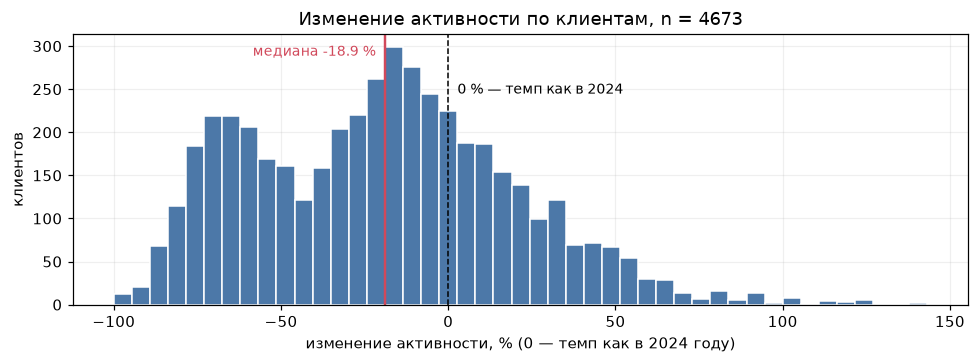

снизили активность: 69.4%; на том же уровне или выше: 30.6%
квартили: 25 % — -52.9 %, 50 % — -18.9 %, 75 % — 6.0 %
падение глубже 90 %: 0.6% клиентов
суммарная потеря когорты: 7056 опер./мес


In [23]:
change = clean["activity_change"].dropna()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(change, bins=45, color="#4c78a8", edgecolor="white")
ax.axvline(0, color="black", ls="--", lw=1)
ax.axvline(change.median(), color="#d1495b", lw=1.6)
ax.annotate(
    f"медиана {change.median():.1f} %",
    xy=(change.median(), ax.get_ylim()[1] * 0.92),
    xytext=(-6, 0), textcoords="offset points", ha="right", color="#d1495b", fontsize=9,
)
ax.annotate("0 % — темп как в 2024", xy=(0, ax.get_ylim()[1] * 0.78), xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.set(
    xlabel="изменение активности, % (0 — темп как в 2024 году)",
    ylabel="клиентов",
    title=f"Изменение активности по клиентам, n = {len(change)}",
)
plt.tight_layout()
plt.show()

print(f"снизили активность: {(change < 0).mean():.1%}; на том же уровне или выше: {(change >= 0).mean():.1%}")
print(f"квартили: 25 % — {change.quantile(0.25):.1f} %, 50 % — {change.median():.1f} %, 75 % — {change.quantile(0.75):.1f} %")
print(f"падение глубже 90 %: {(change < -90).mean():.1%} клиентов")
print(f"суммарная потеря когорты: {COHORT_LOSS:.0f} опер./мес")

Распределение смещено влево от нуля: реже платить стали 69.4 % клиентов, каждый четвёртый потерял больше 52.9 %, медиана −18.9 %. Суммарно когорта теряет 7 056 операций в месяц. Падение глубже 90 % — редкость (0.6 % клиентов), поэтому картина не сводится к «часть клиентов ушла»: у большинства это умеренное, но устойчивое снижение частоты.

### 4.2. Падение не сезонное: в каждом месяце H1 2025 темп ниже того же месяца 2024 года

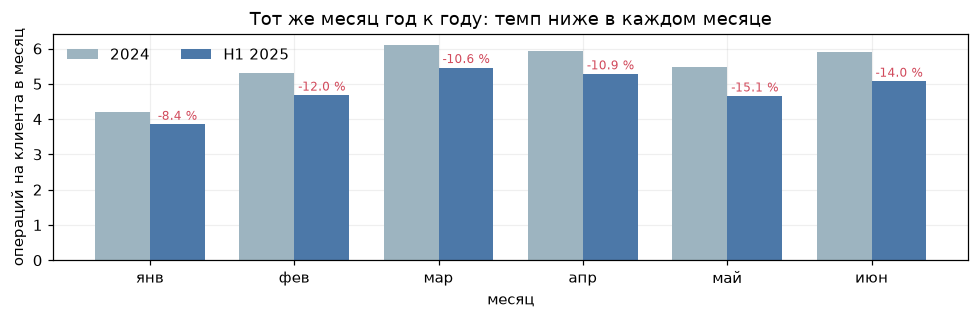

год к году по месяцам, %: янв -8.4, фев -12.0, мар -10.6, апр -10.9, май -15.1, июн -14.0
за 6 месяцев: 32.92 → 28.99 опер./клиента (-12.0 %)


In [24]:
x = np.arange(len(MONTHS))
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(x - 0.19, monthly[2024].to_numpy(), 0.38, label="2024", color="#9db4c0")
ax.bar(x + 0.19, monthly[2025].to_numpy(), 0.38, label="H1 2025", color="#4c78a8")
for i, (a, b) in enumerate(zip(monthly[2024], monthly[2025])):
    ax.annotate(
        f"{(b / a - 1) * 100:.1f} %", xy=(i + 0.19, b), xytext=(0, 3),
        textcoords="offset points", ha="center", fontsize=8, color="#d1495b",
    )
ax.set_xticks(x, MONTHS)
ax.set(xlabel="месяц", ylabel="операций на клиента в месяц", title="Тот же месяц год к году: темп ниже в каждом месяце")
ax.legend(frameon=False, ncols=2)
plt.tight_layout()
plt.show()

yoy_h1 = (monthly[2025] / monthly[2024] - 1) * 100
print("год к году по месяцам, %: " + ", ".join(f"{m} {v:.1f}" for m, v in zip(MONTHS, yoy_h1)))
print(f"за 6 месяцев: {monthly[2024].sum():.2f} → {monthly[2025].sum():.2f} опер./клиента "
      f"({(monthly[2025].sum() / monthly[2024].sum() - 1) * 100:.1f} %)")

Сравнение одинаковых месяцев убирает календарь и разную длину окон. Год к году темп ниже в каждом месяце: от −8.4 % в январе до −15.1 % в мае, за полгода 32.92 → 28.99 операции на клиента (−12.0 %). Декабрьский пик и разное число выходных такую картину не объясняют — падение есть во всех месяцах. Разница между −12.0 % по суммарному темпу и −18.9 % по медиане клиента — в весе: медиана считает каждого клиента одинаково, а поток — пропорционально его активности.

### 4.3. Глубже всех падает массовый сегмент, внутри него — клиенты без приложения

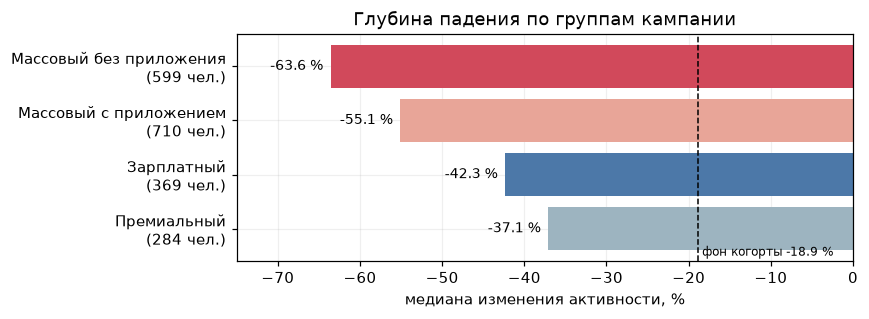

,медиана,клиентов
group_short,,
Массовый без приложения,-63.6,599
Массовый с приложением,-55.1,710
Зарплатный,-42.3,369
Премиальный,-37.1,284



до порога −20 % (клиентов с падением и согласием): 2852


,клиентов,медиана
segment,,
Private,105,-23.3
Зарплатный,665,-22.7
Массовый,1659,-50.6
Премиальный,423,-27.9


In [25]:
grp = groups_data.groupby("group_short", observed=True)["activity_change"].agg(медиана="median", клиентов="size").reindex(ORDER)
bg = clean["activity_change"].median()

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(range(len(grp)), grp["медиана"], color=["#d1495b", "#e8a598", "#4c78a8", "#9db4c0"])
ax.axvline(bg, color="black", ls="--", lw=1)
ax.annotate(f"фон когорты {bg:.1f} %", xy=(bg, 3.5), xytext=(3, 0), textcoords="offset points", fontsize=8)
ax.set_yticks(range(len(grp)), labels=[f"{name}\n({n} чел.)" for name, n in zip(grp.index, grp["клиентов"])])
ax.invert_yaxis()
ax.set_xlim(-75, 0)
for i, v in enumerate(grp["медиана"]):
    ax.annotate(f"{v:.1f} %", xy=(v, i), xytext=(-5, 0), textcoords="offset points", ha="right", va="center", fontsize=9)
ax.set(xlabel="медиана изменения активности, %", title="Глубина падения по группам кампании")
plt.tight_layout()
plt.show()

display(grp.round(1))

falling_cohort = clean.loc[clean["marketing_opt_in"].eq("Да") & clean["activity_change"].lt(0).fillna(False)]
print(f"\nдо порога −20 % (клиентов с падением и согласием): {len(falling_cohort)}")
display(falling_cohort.groupby("segment", observed=True)["activity_change"].agg(клиентов="size", медиана="median").round(1))

Медиана по массовому сегменту −50.6 %, у зарплатного −22.7 %, у премиального −27.9 %,: весь разброс по сегментам создаёт массовый, и он же самый многочисленный — 1 659 из 2 852 клиентов с падением. Внутри массового приложение делит клиентов на две разные группы: без приложения −63.6 % и медиана 24 дня без операций, с приложением −55.1 % и 10 дней. Признак «приложение» не дублирует сегмент (доля владельцев 56–62 % во всех сегментах) и поддаётся действию кампании — установке приложения, — поэтому именно он делит массовый сегмент, а не лояльность, тип карты или источник дохода.

### 4.4. Падение идёт за счёт повседневных трат, а не перетока между категориями

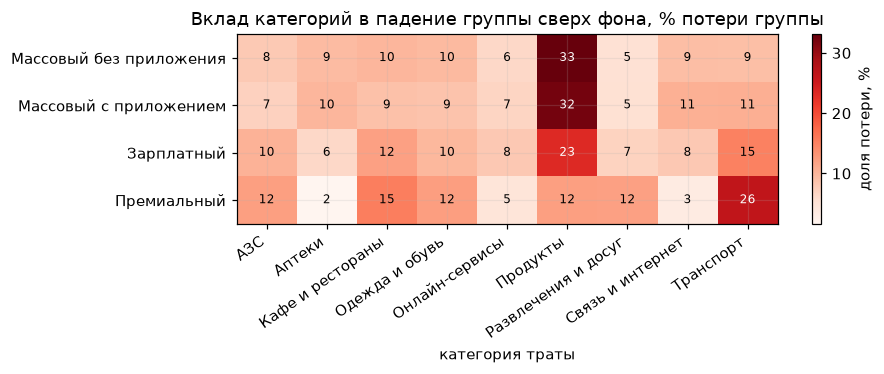

In [26]:
contrib = pd.DataFrame(index=CATEGORIES)
for name, part in groups_data.groupby("group_short", observed=True):
    contrib[name] = cat_delta(part) - BG_CAT        # вклад сверх фона когорты
contrib = contrib.reindex(columns=ORDER)
share = contrib / contrib.sum() * 100               # в % от всей потери группы

fig, ax = plt.subplots(figsize=(8.5, 3.5))
im = ax.imshow(share.T.to_numpy(), cmap="Reds", aspect="auto")
ax.set_xticks(range(len(CATEGORIES)), labels=CATEGORIES, rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), labels=ORDER)
for i in range(share.shape[1]):
    for j in range(share.shape[0]):
        v = share.T.to_numpy()[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > share.to_numpy().max() * 0.55 else "black")
ax.set(xlabel="категория траты", title="Вклад категорий в падение группы сверх фона, % потери группы")
fig.colorbar(im, ax=ax, label="доля потери, %")
plt.tight_layout()
plt.show()

На графике — вклад категории в падение группы сверх фона когорты (чтобы общий тренд банка не записывался в причину группы), в % от потери группы. У массового сегмента треть потери — «Продукты» (33.1 % без приложения, 32.2 % с приложением), остальное делят «Кафе», «Аптеки», «Одежда», «Связь», «Транспорт» — по 5–10 % каждая. У зарплатного добавляется «Транспорт» (15.2 %), у премиального он выходит на первое место — 26.4 %, а «Аптеки» дают только 1.6 %: там сокращаются поездки и рестораны, а не ежедневные покупки. Роста нет ни в одной из 9 категорий ни в одной группе — структура трат не перестроилась, сократилась частота пользования картой.

## 5. Группы для кампании

Четыре группы, 1 962 клиента — 98.1 % лимита в 2 000. «б/прил.» — без мобильного приложения, «с прил.» — с приложением.


In [27]:
SHORT = {"Массовый без приложения": "Массовый б/прил.", "Массовый с приложением": "Массовый с прил."}

rows = []
for name, part in groups_data.groupby("group_short", observed=True):
    rows.append({
        "группа": name,
        "клиентов": len(part),
        "опер./мес 2024 → H1 2025": f"{part['2024_activity'].median():.1f} → {part['2025_activity'].median():.1f}",
        "Δ, %": part["activity_change"].median(),
        "потеря/мес": round(part["loss"].sum()),
        "% клиентов": len(part),
        "% потери": part["loss"].sum(),
    })

groups_table = pd.DataFrame(rows).set_index("группа").reindex(ORDER)
groups_table["% клиентов"] = groups_table["% клиентов"] / groups_table["% клиентов"].sum() * 100
groups_table["% потери"] = groups_table["% потери"] / groups_table["% потери"].sum() * 100
groups_table = groups_table.rename(index=SHORT)

display(groups_table.round(1))

lost = groups_table["потеря/мес"].sum()
print(f"итого {groups_table['клиентов'].sum()} чел. (лимит 2 000, минимум в группе {groups_table['клиентов'].min()}); "
      f"потеря {lost:.0f} из {COHORT_LOSS:.0f} опер./мес когорты — {lost / COHORT_LOSS:.1%}; "
      f"campaign_list.csv: {campaign['client_id'].nunique()} клиентов, дублей {int(campaign['client_id'].duplicated().sum())}")

,клиентов,опер./мес 2024 → H1 2025,"Δ, %",потеря/мес,% клиентов,% потери
группа,,,,,,
Массовый б/прил.,599,4.2 → 1.5,-63.6,1722,30.5,31.5
Массовый с прил.,710,4.3 → 1.8,-55.1,1836,36.2,33.6
Зарплатный,369,5.8 → 2.8,-42.3,1091,18.8,20.0
Премиальный,284,5.9 → 3.3,-37.1,818,14.5,15.0


итого 1962 чел. (лимит 2 000, минимум в группе 284); потеря 5467 из 7056 опер./мес когорты — 77.5%; campaign_list.csv: 1962 клиентов, дублей 0


**1. Массовый сегмент, приложение не установлено.** 599 человек — 30.5 % групп и 31.5 % потери. Активность 4.2 → 1.5 опер./мес, медиана −63.6 %, у 72.5 % падение больше чем вдвое, 41.2 % не платили больше 30 дней. За счёт чего: уход из повседневных трат — «Продукты» −0.60 опер./клиента в месяц сверх фона, дальше «Кафе» −0.18, «Одежда» и «Аптеки» −0.17. \
**2. Массовый сегмент с приложением.** 710 человек — 36.2 % и 33.6 % потери. Активность 4.3 → 1.8, медиана −55.1 %, у 56.2 % падение больше чем вдвое, 26.5 % не платили больше 30 дней. За счёт чего: та же повседневная корзина, но мягче — «Продукты» −0.49 сверх фона, «Транспорт» и «Связь» −0.16 и −0.16. \
**3. Зарплатный сегмент.** 369 человек — 18.8 % и 20.0 % потери. База выше: 5.8 → 2.8 опер./мес, медиана −42.3 %, у 42.0 % падение больше чем вдвое. За счёт чего: падение ровное по всем категориям — «Продукты» −0.44, «Транспорт» −0.29, «Кафе» −0.23. \
**4. Премиальный сегмент.** 284 человека — 14.5 % и 15.0 % потери. 5.9 → 3.3 опер./мес, медиана −37.1 %, у 28.2 % падение больше чем вдвое. За счёт чего: сократились поездки и рестораны — «Транспорт» −0.48 и «Кафе и рестораны» −0.28, тогда как «Аптеки» всего −0.03. \
**Пересечений нет.** Группы заданы сегментом, а сегменты не пересекаются; приложение делит только массовый сегмент и в нём задано однозначно. Каждый клиент попадает ровно в одну группу по построению правила, поэтому отдельное правило разрешения конфликтов не нужно.

## 6. Кого не включаем и почему

In [28]:
f = funnel.set_index("шаг")["клиентов"]
consent = clean["marketing_opt_in"].eq("Да")
change = clean["activity_change"]
falling = change.lt(0).fillna(False)      # 9 клиентов без операций в H1 2025: изменение не определено
deep = change.le(-20).fillna(False)
no_2025 = change.isna()
in_campaign = clean["client_id"].isin(campaign["client_id"])

excl = pd.DataFrame(
    [
        ("клиентов в справочнике после очистки", int(f.iloc[0]), "—"),
        ("нет ни одной состоявшейся операции за 18 мес.", int(f.iloc[1]), "наблюдать нечего"),
        ("карта открыта в 2024–2025: базовый период неполный", int(f.iloc[2]), "сравнивать периоды не с чем"),
        ("меньше 1 операции в месяц в базе 2024", int(f.iloc[3]), "отношение двух периодов неустойчиво"),
        ("нет согласия на коммуникацию", int((~consent).sum()), "обращаться нельзя"),
        ("активность не упала или выросла", int((consent & ~falling & ~no_2025).sum()), "другая задача: возвращать нечего"),
        ("падение в пределах −20…0 %", int((consent & falling & ~deep).sum()), "неотличимо от шума (σ = 16–19 %)"),
        ("Private: группа меньше 150 человек", int((consent & falling & deep & ~in_campaign).sum()), "порог 150 клиентов задан условием"),
    ],
    columns=["шаг", "клиентов", "почему"],
).set_index("шаг")

display(excl)
excluded = int(excl["клиентов"].iloc[1:].sum())
print(f"\nисключено всего: {excluded}; остаётся в кампании {int(in_campaign.sum())} "
      f"(сходится: {int(f.iloc[0]) - excluded == int(in_campaign.sum())})")

,клиентов,почему
шаг,,
клиентов в справочнике после очистки,5649,—
нет ни одной состоявшейся операции за 18 мес.,15,наблюдать нечего
карта открыта в 2024–2025: базовый период неполный,789,сравнивать периоды не с чем
меньше 1 операции в месяц в базе 2024,172,отношение двух периодов неустойчиво
нет согласия на коммуникацию,549,обращаться нельзя
активность не упала или выросла,1272,другая задача: возвращать нечего
падение в пределах −20…0 %,836,неотличимо от шума (σ = 16–19 %)
Private: группа меньше 150 человек,54,порог 150 клиентов задан условием



исключено всего: 3687; остаётся в кампании 1962 (сходится: True)


**Без согласия на коммуникацию** — 549 клиентов когорты: обращаться к ним нельзя, и ограничение не зависит от сегмента (согласие дают 87–88 % в каждом). **Без падения или с ростом** — 1 272 клиента. **Падение в пределах −20…0 %** — 836 клиентов (медиана около −11 %): при относительном стандартном отклонении 16–19 % такое изменение неотличимо от случайных колебаний, и коммуникация была бы реакцией на шум.

## 7. Что проверили и что не подтвердилось

✓ — гипотеза подтвердилась, ✗ — не подтвердилась.


- ✗ **Падение объясняется городом.** Медиана в массовом сегменте по 6 городам: −61…−56 % — география картину не объясняет.
- ✗ **Наличие приложения различает сегменты.** Доля клиентов с приложением 56–62 % во всех сегментах — признак не дублирует сегментацию.
- ✗ **Падение — переток трат между категориями.** Рост есть в 0 из 36 ячеек (9 категорий × 4 группы): структура трат не перестроилась, сократилась частота.
- ✗ **Падение — сезонность и календарь.** Год к году темп ниже в 6 из 6 месяцев: от −15.1 % до −8.4 %.
- ✗ **Сдвиг каналов сам по себе — потеря активности.** Доля «Карты» 64 → 55 %, «Токена» 17 → 27 % при падении темпа −12.0 %: перераспределение каналов не создаёт потерю операций.


## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал — 23 решения в `cleaning_log.csv`. Ниже сводка по полям: что найдено, сколько строк затронуто, что сделано.

In [29]:
log = cleaning_log.copy()
log["n_rows"] = pd.to_numeric(log["n_rows"], errors="coerce")

FIELDS_APPENDIX = [
    "все поля clients.csv", "все поля transactions.csv", "client_id", "city", "category",
    "monthly_income", "currency", "status", "channel", "card_open_date",
]
appendix = (
    log[log["field"].isin(FIELDS_APPENDIX)]
    .groupby("field", observed=True)
    .agg(**{
        "что найдено": ("issue", lambda s: "; ".join(dict.fromkeys(s))),
        "строк": ("n_rows", "sum"),
        "сделано": ("action", lambda s: ", ".join(dict.fromkeys(s))),
    })
    .reindex(FIELDS_APPENDIX)
)
appendix.index.name = "поле"

# без обрезки текста в ячейках таблицы
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(appendix)

,что найдено,строк,сделано
поле,,,
все поля clients.csv,полные дубли строк,40,удалено
все поля transactions.csv,полные дубли строк,1281,удалено
client_id,"один идентификатор с разными атрибутами; операции клиентов, которых нет в справочнике",30874,удалено
city,разнобой написания одного города,5649,нормализация
category,разнобой написания категории и лишние варианты,592851,нормализация
monthly_income,сентинел -999 вместо отсутствия значения; часть значений записана в тысячах рублей; пропуски; значения выше границы Тьюки,1172,"исправлено, оставлено"
currency,три валюты в одном поле суммы,2489,исправлено
status,в файле есть отклонённые операции и возвраты,18815,ограничено
channel,в канале СБП в фев–мар 2025 потеряны строки (7.9% и 7.7% месяца),97382,ограничено


### 8.2. Методика

**Метрика.** Для клиента *c* и периода *P*:

$$
\mathrm{rate}(c,P)=\frac{n_{c,P}}{L_P},
\qquad
\mathrm{change}(c)=\frac{\mathrm{rate}(c,2025)}{\mathrm{rate}(c,2024)}-1,
$$

где $n_{c,P}$ — число операций клиента *c* в периоде *P*, $L_P$ — длина периода в месяцах. Окна: 2024 — 12 месяцев, H1 2025 — 6 месяцев. \
**Операции.** `status = «успешно»`, дата внутри 2024-01-01…2025-06-30 (граница сравнивается по дате, время внутри суток сохраняется), каналы «Карта», «Токен», «Онлайн-банк», категория нормализована до 9 значений, суммы приведены к рублю по среднему курсу ЦБ РФ за месяц операции. \
**Когорта.** `clean_data.parquet`: карта открыта до 2024-01-01 и в базе 2024 не меньше 1 операции в месяц без СБП — 4 673 клиента. Их операции — `clean_ops.parquet` (465 745 строк). Воронка отбора — `clean_funnel.csv`.

### 8.3. Использование ИИ

- ИИ-ассистент использовался в основном для проверки корректности интерпертации полученных данных при анализе и советов как эти данные дальше лучше преобразовать, когда не было уверенности какой путь лучше выбрать.
- Им же предложена проверка непрерывности `txn_id` по месяцам — она и выявила выпавшие строки февраля–марта 2025; расчёт и трактовку проверил по кросс-таблицам каналов и по разрывам в последовательности ключей.
- Также использовался для ускорения переноса необходимых данных в отчет.
- Группы и формулировки переписаны вручную: ассистент предлагал группировать по величине падения, но от этого отказались — правило должно описывать клиента, а не порог.